In [1]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import AxesGrid
from salvaged import *
run = 'earth27/'
datadir = '../data/'+run
prefix=''

In [6]:
ptimes=[9.9]
tim=[200.0]
t_eps=0.001
ThisPatch = RamsesMHDPatch
verbose=False
skipped=[]
gamma = 1.4
orbit_radius_au = 1.0
omega = [0.0,0.0,1.0]
pl_pos= [0.0,1.0,0.0]
v_headwind = 0.0   # the headwind the planet feels
v_accretion = 0.0  # accretion rate
density_cgs=3e-12  # external density
times=np.linspace(1,99,99)/10.
    
patches = get_data(time=tim[0],t_eps=t_eps,datadir=datadir)

159 patches collected for time 200.0


yt : [INFO     ] 2017-03-17 11:54:28,956 Parameters: current_time              = 0.0
yt : [INFO     ] 2017-03-17 11:54:28,957 Parameters: domain_dimensions         = [30 30 30]
yt : [INFO     ] 2017-03-17 11:54:28,959 Parameters: domain_left_edge          = [-2700. -2700. -2700.]
yt : [INFO     ] 2017-03-17 11:54:28,961 Parameters: domain_right_edge         = [ 2700.  2700.  2700.]
yt : [INFO     ] 2017-03-17 11:54:28,962 Parameters: cosmological_simulation   = 0.0
yt : [INFO     ] 2017-03-17 11:54:29,793 xlim = -2700.000000 2700.000000
yt : [INFO     ] 2017-03-17 11:54:29,794 ylim = -2700.000000 2700.000000
yt : [INFO     ] 2017-03-17 11:54:29,796 xlim = -2700.000000 2700.000000
yt : [INFO     ] 2017-03-17 11:54:29,797 ylim = -2700.000000 2700.000000
yt : [INFO     ] 2017-03-17 11:54:29,800 Making a fixed resolution buffer of (('gas', 'density')) 800 by 800



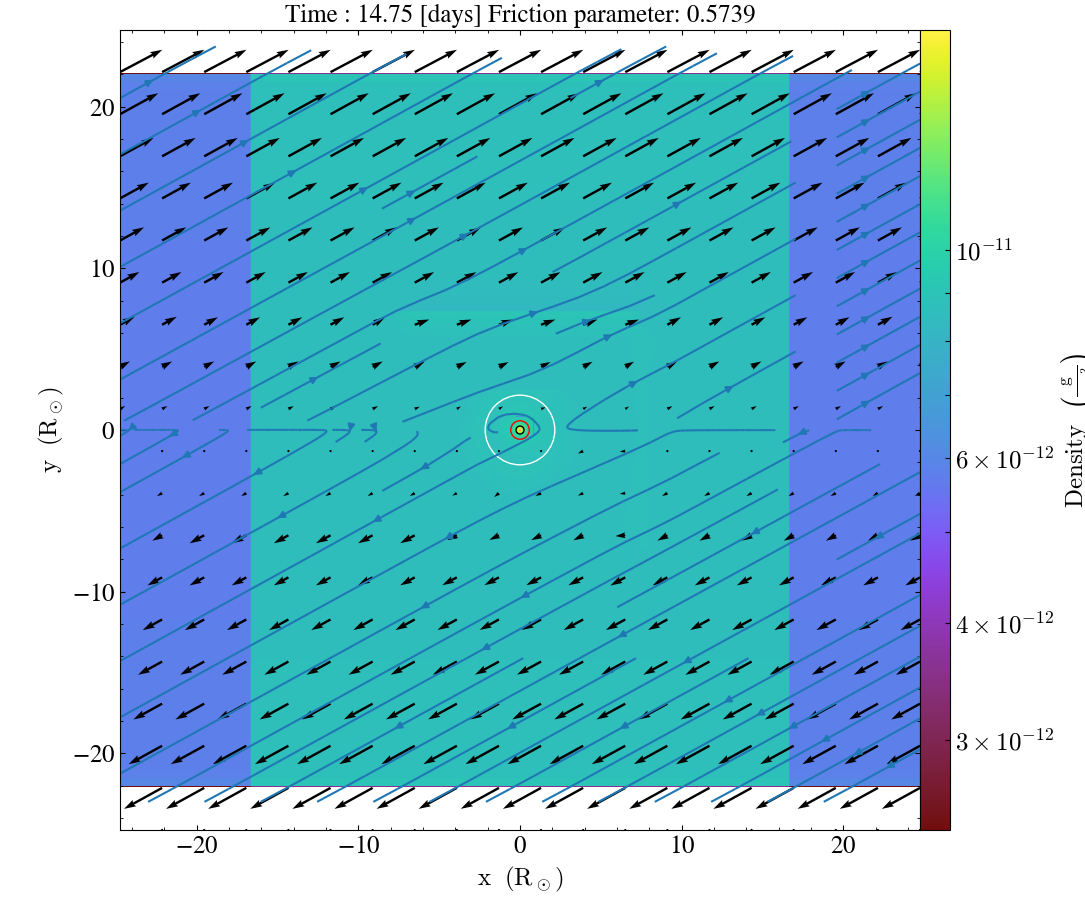

In [7]:
dic=make_yt_dict(patches)
n=patches[0].n
sz=2700
pl_rad=27.
pl_mass=1.0
csound=1.0
bond_rad = pl_mass*sc.scaling().g/csound**2
hill_rad = 235
ds = load_yt(dic,n,sz)
frc_time = 500.
frc_force = 0.5
f_sc = 1-np.exp(-(tim[0]/frc_time)**2)*frc_force
fig = plt.figure()
#carg=dict

#plt.savefig('multiplot_2x2_coordaxes_slice.png')
#ds.current_time=patches[0].time*sc.scaling().t/3600.
slc=yt.SlicePlot(ds=ds,axis="z",fields=["density"],center=[0,0,0])
slc.annotate_velocity(factor=40, normalize=False)
slc.annotate_streamlines('velocity_x', 'velocity_y')
slc.time_unit=sc.scaling().t
slc.annotate_sphere(center=[0.0, 0.0, 0.0], radius=1, circle_args={'color':'magenta'})
slc.annotate_sphere(center=[0.0, 0.0, 0.0], radius=pl_rad, circle_args={'color':'black'})
slc.annotate_sphere(center=[0.0, 0.0, 0.0], radius=bond_rad, circle_args={'color':'red'})
slc.annotate_sphere(center=[0.0, 0.0, 0.0], radius=hill_rad, circle_args={'color':'white'})
slc.current_time=patches[0].time*sc.scaling().t/3600./24.
slc.annotate_title("Time : %.2f [days]" % (patches[0].time*sc.scaling().t/3600./24.)+" Friction parameter: %.4f" %f_sc)
#slc.set_zlim('density',6e-12,3e-11)
#slc.annotate_timestamp()
#slc.zoom(10)
#slc.annotate_grids()
slc.show()

yt : [INFO     ] 2017-03-17 11:52:30,160 Making a fixed resolution buffer of (('gas', 'density')) 800 by 800



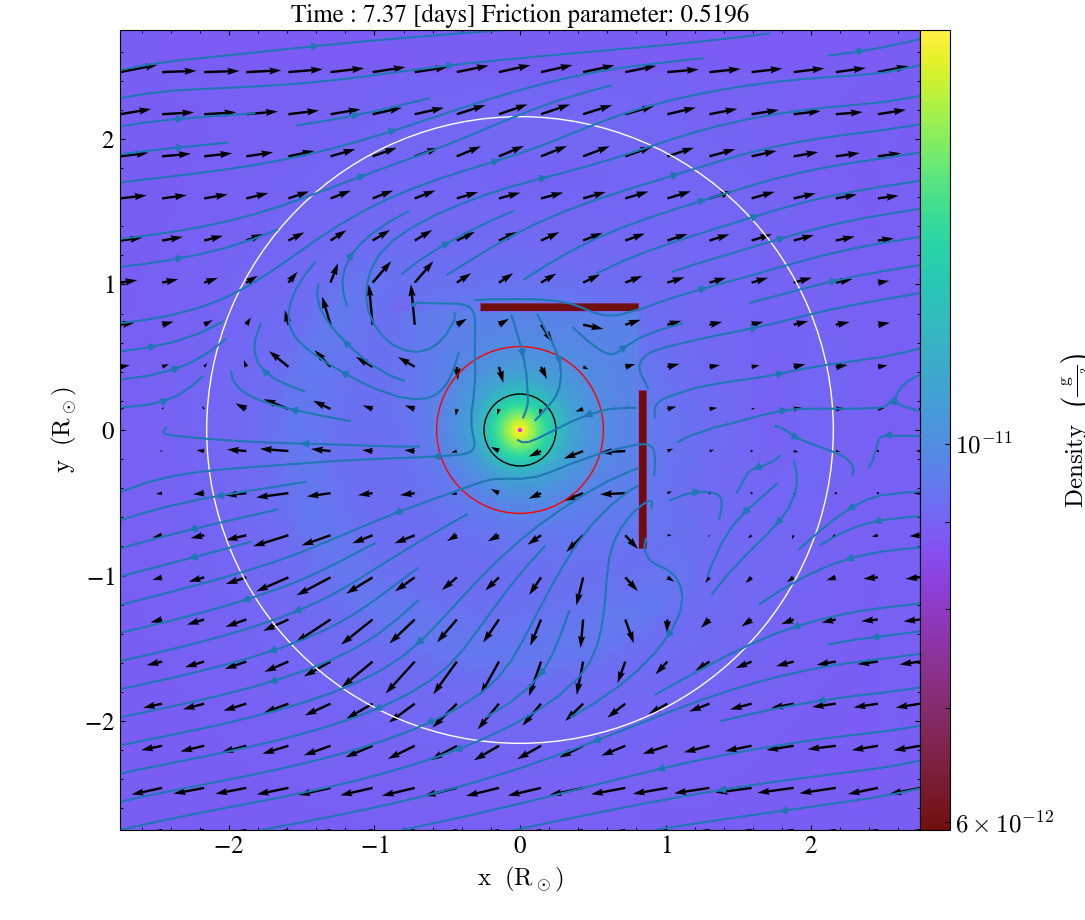

In [5]:
slc.zoom(3)
#slc.set_zlim('temperature',200,1000)
#slc.annotate_grids()
slc.show()

186 patches collected for time 300.0


In [17]:
slc.save('earth27.png')

yt : [INFO     ] 2017-03-15 18:49:30,293 Saving plot earth27.png


['earth27.png']

In [202]:
f_sc, frc_time

(0.018315638888734179, 2000.0)

In [203]:
np.exp(-1.)

0.36787944117144233

In [6]:
sc.scaling().temp

242.2828999782719

In [16]:
ee=ds.all_data()

In [4]:
patches[0].temp.shape

AttributeError: 'list' object has no attribute 'shape'

In [12]:
gn =patches[0].gn; ng = patches[0].nghost

In [13]:
u=[a-b for a,b in zip(gn,ng)]

In [14]:
u

[32, 32, 32]